# Шаг 1. Знакомимся с данными: кошки и собаки из CIFAR-10

В сессии 3 сеть узнавала цифры MNIST: белая цифра на чёрном фоне, всегда в центре, всегда одного размера.
Теперь задача сложнее и ближе к жизни — **отличить кошку от собаки на фотографии**.

Берём набор **CIFAR-10**: 60 000 маленьких цветных фотографий 32 × 32 из 10 классов (самолёты, машины, птицы, кошки, олени,
собаки, лягушки, лошади, корабли, грузовики). Нам нужны только два класса — **кошки и собаки**:
- 10 000 картинок для обучения (5 000 кошек и 5 000 собак);
- 2 000 картинок для проверки (по 1 000).

Пара «кошка — собака» — самая трудная в CIFAR-10: у обоих есть шерсть, уши, глаза и четыре лапы, их снимают в похожих комнатах.

**Структура примера (алгоритм):**
1. Загружаем обучающую и проверочную части, считаем картинки каждого класса.
2. Смотрим на одну картинку изнутри: форма тензора и числа.
3. Рисуем таблицу из 32 картинок с подписями.
4. Раскладываем одну фотографию на три цветовых канала.
5. Сравниваем с MNIST: почему полносвязной сети здесь будет трудно.

In [ ]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session01–session05 и dataset).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session04")  # здесь лежит common.py и сохраняются результаты
    sys.path.insert(0, os.getcwd())

    # Набор данных скачивается на Диск один раз, потом берётся готовый
    from torchvision import datasets

    datasets.CIFAR10(f"{COLAB_ROOT}/data", download=True)

## Общий модуль `common.py`

Во всех примерах этой сессии используется модуль `common.py` из этой же папки:

| Имя | Что делает |
|-----|------------|
| `CatsDogs(train, transform)` | набор данных: только кошки и собаки из CIFAR-10. Обучающий (`train=True`) — 10 000 картинок, проверочный — 2 000. Метки: 0 — кошка, 1 — собака |
| `CLASSES`, `CLASSES_RU` | названия классов: `["cat", "dog"]` и `["кошка", "собака"]` |
| `MLP` | полносвязная сеть из сессии 3, только вход 3 × 32 × 32 = 3072 числа |
| `SimpleCNN(dropout)` | простая свёрточная сеть: три блока «свёртка → ReLU → пулинг» и классификатор |
| `train(model, train_set, test_set, epochs)` | цикл обучения из сессии 3; после каждой эпохи пишет точность на обучающих и проверочных картинках |
| `accuracy`, `predict_all` | точность сети на наборе и вероятности классов для всех картинок |
| `save_model`, `load_model`, `load_history` | сохранить / загрузить веса (`*.pt`) и историю обучения (`*.json`) |
| `count_params(model)` | сколько весов в сети |
| `show()` | показать графики matplotlib |

> Запускайте примеры из папки `session04`, иначе `import common` не найдёт модуль.
> Библиотеки: `pip install -r requirements.txt`. CIFAR-10 берётся из локальной папки `data/cifar-10-batches-py`, интернет не нужен.

## 1. Загружаем данные

`CatsDogs(train=True)` при первом вызове скачивает весь CIFAR-10, а затем оставляет только кошек и собак.
`labels.bincount()` считает, сколько раз встречается каждая метка: сколько картинок с меткой 0 (кошки) и с меткой 1 (собаки).
Классы **сбалансированы** (их поровну) — значит, «тупая» сеть, которая всегда отвечает «кошка», угадает ровно 50%.
Это **нижняя планка**: всё, что выше 50%, сеть действительно чему-то научилась.

In [1]:
import matplotlib.pyplot as plt

from common import CLASSES, CLASSES_RU, CatsDogs, show

train = CatsDogs(train=True)   # читается из локальной папки data/cifar-10-batches-py
test = CatsDogs(train=False)

print("Картинок для обучения:", len(train))
print("Картинок для проверки:", len(test))
for label, count in enumerate(train.labels.bincount().tolist()):
    print(f"  {CLASSES_RU[label]}: {count}")

Картинок для обучения: 10000
Картинок для проверки: 2000
  кошка: 5000
  собака: 5000


## 2. Одна картинка изнутри

`train[0]` — пара **(картинка, метка)**. Картинка — тензор формы **`(3, 32, 32)`**:
3 канала (красный, зелёный, синий — порядок RGB, не BGR, как в OpenCV!), 32 строки, 32 столбца.
Числа — от 0 до 1. Всего `3 · 32 · 32 = 3072` числа — почти в 4 раза больше, чем 784 пикселя MNIST.

`image[:, 0, 0]` — три числа левого верхнего пикселя: его красная, зелёная и синяя составляющие.

In [2]:
image, label = train[0]
print("Форма картинки:", tuple(image.shape), "— 3 канала, 32×32 пикселя")
print("Всего чисел:", image.numel())
print("Это:", CLASSES_RU[label])
print("Левый верхний пиксель (R, G, B):", [round(v, 2) for v in image[:, 0, 0].tolist()])

Форма картинки: (3, 32, 32) — 3 канала, 32×32 пикселя
Всего чисел: 3072
Это: кошка
Левый верхний пиксель (R, G, B): [0.49, 0.49, 0.45]


## 3. Таблица из 32 картинок

matplotlib ждёт цветную картинку в виде **`(высота, ширина, 3)`**, а у PyTorch каналы идут первыми — `(3, высота, ширина)`.
`image.permute(1, 2, 0)` переставляет оси: была ось 0 (каналы) → станет последней.

Картинки очень маленькие, поэтому выглядят размытыми. Но человек всё равно почти всегда узнаёт, кто на них.

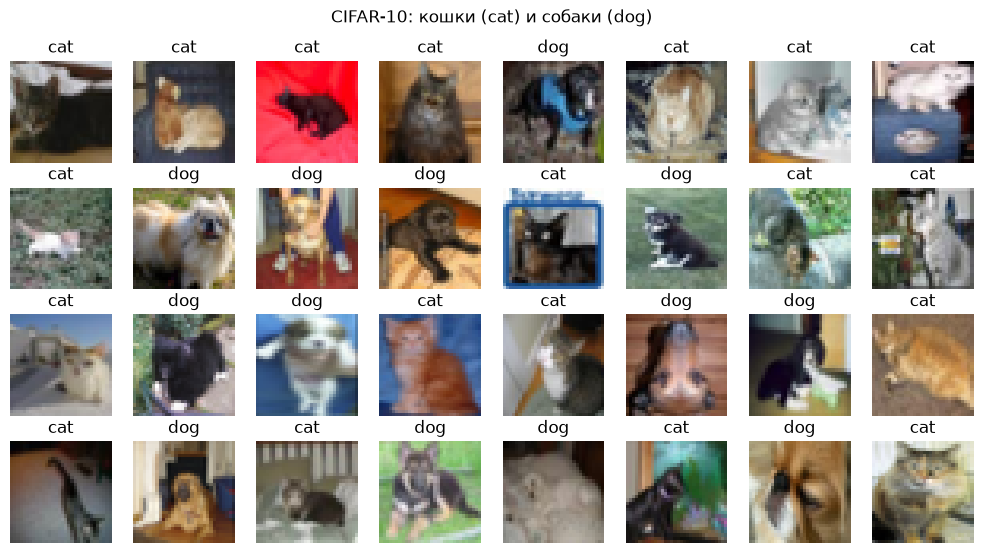

In [3]:
fig, axes = plt.subplots(4, 8, figsize=(10, 5.6))
for i, ax in enumerate(axes.flat):
    image, label = train[i]
    ax.imshow(image.permute(1, 2, 0))  # (3, 32, 32) → (32, 32, 3) для matplotlib
    ax.set_title(CLASSES[label])
    ax.axis("off")
fig.suptitle("CIFAR-10: кошки (cat) и собаки (dog)")
plt.tight_layout()
plt.savefig("cats_dogs_grid.png", dpi=100)
show()

## 4. Три цветовых канала

Каждый канал — это отдельная серая картинка 32 × 32: чем светлее пиксель, тем больше в нём этого цвета.
Свёрточная сеть смотрит на **все три канала сразу**: каждый её фильтр имеет размер `3 × 3 × 3` — по кусочку 3 × 3 в каждом канале.

`interpolation="nearest"` рисует пиксели квадратиками без сглаживания — так видно настоящее разрешение 32 × 32.

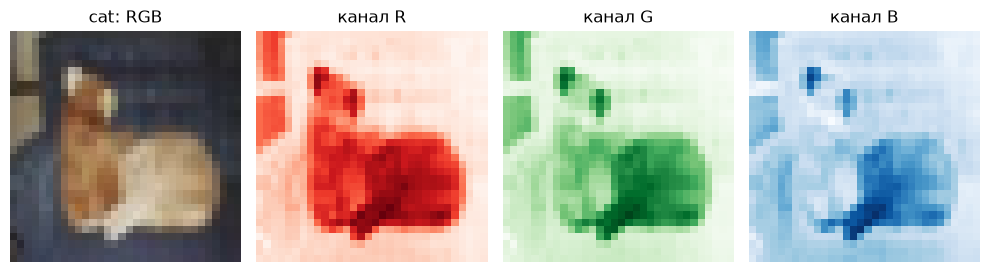

In [4]:
image, label = train[1]
fig, axes = plt.subplots(1, 4, figsize=(10, 2.9))
axes[0].imshow(image.permute(1, 2, 0), interpolation="nearest")
axes[0].set_title(f"{CLASSES[label]}: RGB")
for ax, channel, name, cmap in zip(axes[1:], image, ["R", "G", "B"], ["Reds", "Greens", "Blues"]):
    ax.imshow(channel, cmap=cmap, interpolation="nearest")
    ax.set_title(f"канал {name}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig("one_image.png", dpi=100)
show()

## 5. Почему это сложнее MNIST

| | MNIST | Кошки и собаки |
|---|---|---|
| Цвет | серый, 1 канал | цветной, 3 канала |
| Положение | цифра всегда в центре | животное где угодно, любого размера |
| Фон | чёрный, пустой | диван, трава, ковёр, люди |
| Поза | цифры пишут похоже | спит, бежит, морда крупным планом, вид сбоку |

В сессии 3 мы выяснили: полносвязной сети **всё равно, где какой пиксель** — она запоминает,
«какие пиксели обычно яркие у этого класса». Для цифр в центре этого хватало.
Но кошка, сдвинутая на 5 пикселей вправо, для такой сети — совершенно другой набор чисел.
Нужна сеть, которая ищет **узоры** (уши, глаза, шерсть) **в любом месте** картинки. Это и есть **свёрточная сеть**.

## Попробуйте сами

1. Покажите 32 картинки из проверочного набора `test`. Есть ли картинки, где вы сами не уверены?
2. Найдите первые 10 собак: `(train.labels == 1).nonzero()[:10]`.
3. Посчитайте средний цвет кошек и собак: `train.images[train.labels == 0].mean((0, 2, 3))`. Есть ли разница?
4. Посмотрите на одну картинку, увеличенную без сглаживания (`interpolation="nearest"`). Что потерялось при уменьшении до 32 × 32?